In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis

%matplotlib inline
sns.set_theme(style="whitegrid")


In [2]:
file_path = r"C:\Users\shilp\OneDrive\Documents\GitHub\lab-eda-univariate\amz_uk_price_prediction_dataset.csv" 
df = pd.read_csv(file_path)

In [6]:
df.head()


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [7]:
df.shape


(2443651, 9)

In [10]:
df = df.dropna(subset=['category', 'price', 'rating'])
print(f"Dataset successfully loaded. Active data size: {df.shape}")

KeyError: ['rating']

In [11]:
df = df.dropna(subset=['category', 'price', 'rating'])
print(f"Dataset successfully loaded. Active data size: {df.shape}")

KeyError: ['rating']

In [12]:
# 2. FIX KEYERROR: Check and rename 'stars' to 'rating' immediately
if 'stars' in df.columns:
    df = df.rename(columns={'stars': 'rating'})

In [13]:
df = df.dropna(subset=['category', 'price', 'rating'])
print(f"Dataset successfully loaded. Active data size: {df.shape}")

Dataset successfully loaded. Active data size: (2443651, 9)


In [14]:
print("\n" + "="*50 + "\nPART 1: PRODUCT CATEGORY ANALYSIS\n" + "="*50)


PART 1: PRODUCT CATEGORY ANALYSIS


In [15]:
category_counts = df['category'].value_counts()
category_proportions = df['category'].value_counts(normalize=True) * 100

freq_table = pd.DataFrame({
    'Total Listings': category_counts,
    'Market Share (%)': category_proportions
})
print("\n--- Top 5 Most Listed Product Categories ---")
print(freq_table.head(5))


--- Top 5 Most Listed Product Categories ---
                                        Total Listings  Market Share (%)
category                                                                
Sports & Outdoors                               836265         34.221949
Beauty                                           19312          0.790293
Handmade Clothing, Shoes & Accessories           19229          0.786896
Bath & Body                                      19092          0.781290
Birthday Gifts                                   18978          0.776625


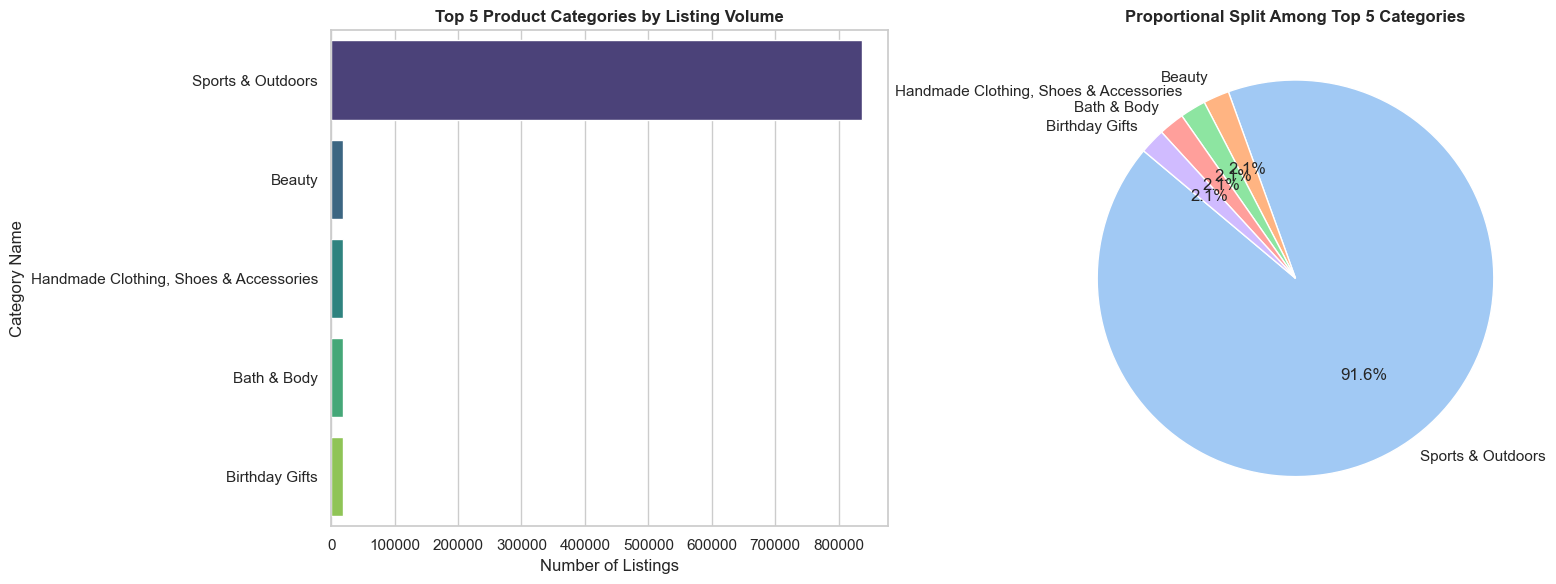

In [16]:
top_5_cats = freq_table.head(5)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(ax=axes[0], x=top_5_cats['Total Listings'], y=top_5_cats.index, palette='viridis', hue=top_5_cats.index, legend=False)
axes[0].set_title('Top 5 Product Categories by Listing Volume', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Number of Listings')
axes[0].set_ylabel('Category Name')

axes[1].pie(top_5_cats['Total Listings'], labels=top_5_cats.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
axes[1].set_title('Proportional Split Among Top 5 Categories', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# PART 2: DELVING INTO PRODUCT PRICING
# =========================================================================
print("\n" + "="*50 + "\nPART 2: PRODUCT PRICING ANALYSIS\n" + "="*50)




PART 2: PRODUCT PRICING ANALYSIS


In [19]:
# Ensure numeric parsing and remove missing value fields
df['price'] = pd.to_numeric(df['price'], errors='coerce')
price_df = df.dropna(subset=['price'])

price_mean = price_df['price'].mean()
price_median = price_df['price'].median()
price_mode = price_df['price'].mode()[0] if not price_df['price'].mode().empty else np.nan

In [20]:
# 2. Measures of Dispersion
price_var = price_df['price'].var()
price_std = price_df['price'].std()
price_min = price_df['price'].min()
price_max = price_df['price'].max()
price_range = price_max - price_min
price_iqr = price_df['price'].quantile(0.75) - price_df['price'].quantile(0.25)

In [21]:
print("\n--- Price Central Tendency ---")
print(f"Mean Price:   £{price_mean:.2f}")
print(f"Median Price: £{price_median:.2f}")
print(f"Mode Price:   £{price_mode:.2f}")


--- Price Central Tendency ---
Mean Price:   £89.24
Median Price: £19.09
Mode Price:   £9.99


In [22]:
print("\n--- Price Dispersion Measures ---")
print(f"Variance:           {price_var:.2f}")
print(f"Standard Deviation: £{price_std:.2f}")
print(f"Price Range:        £{price_range:.2f} (Min: £{price_min:.2f} to Max: £{price_max:.2f})")
print(f"Interquartile Range:£{price_iqr:.2f}")



--- Price Dispersion Measures ---
Variance:           119445.49
Standard Deviation: £345.61
Price Range:        £100000.00 (Min: £0.00 to Max: £100000.00)
Interquartile Range:£36.00


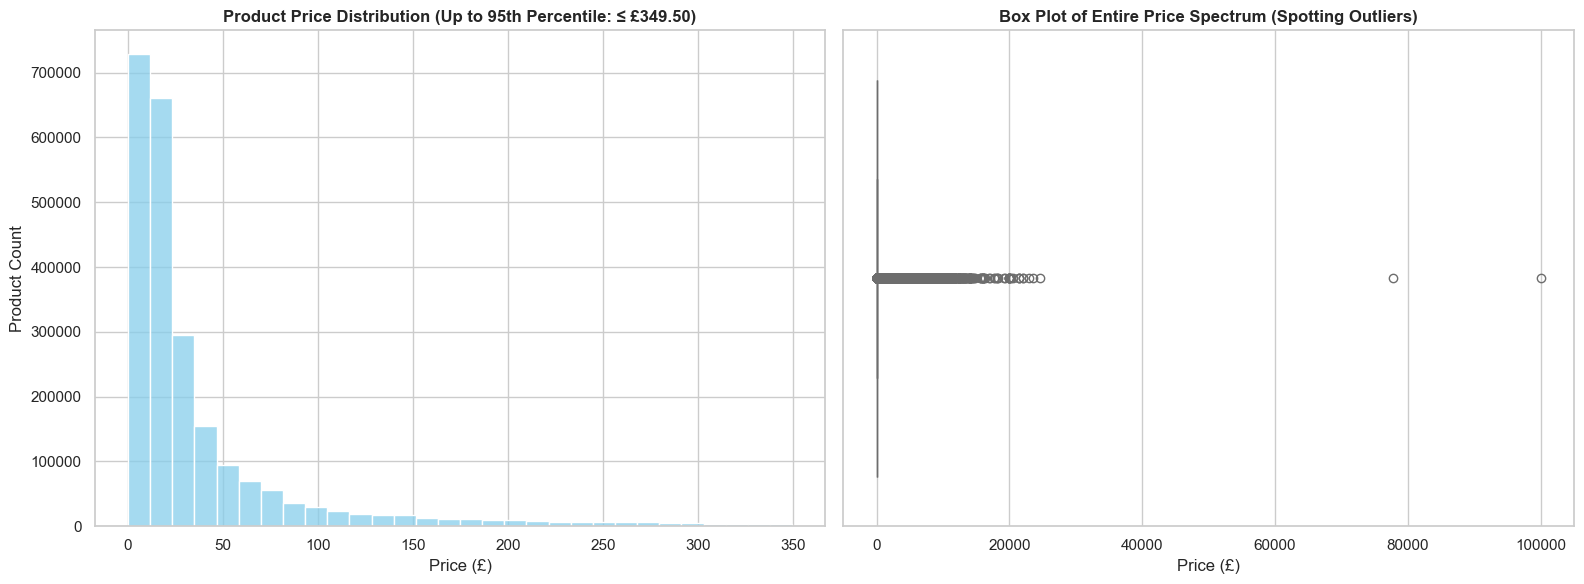

In [26]:
# 3. Visualizations
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Solution for Compressed Diagrams: Cap histogram visualization at the 95th Percentile
price_cutoff = price_df['price'].quantile(0.95)
filtered_prices = price_df[price_df['price'] <= price_cutoff]['price']

# Sub-plot 1: Clean Histogram (KDE disabled to circumvent system freezes)
sns.histplot(ax=axes[0], data=filtered_prices, bins=30, kde=False, color='skyblue')
axes[0].set_title(f'Product Price Distribution (Up to 95th Percentile: ≤ £{price_cutoff:.2f})', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Price (£)')
axes[0].set_ylabel('Product Count')
# Sub-plot 2: Box Plot (Maintains full dataset scope to expose extreme outliers)
sns.boxplot(ax=axes[1], x=price_df['price'], color='salmon')
axes[1].set_title('Box Plot of Entire Price Spectrum (Spotting Outliers)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Price (£)')

plt.tight_layout()
plt.show()


In [27]:
print("\n" + "="*50 + "\nPART 3: CUSTOMER RATINGS ANALYSIS\n" + "="*50)

# Ensure numeric parsing
df['rating'] = pd.to_numeric(df['rating'], errors='coerce')

# Apply critical filter to discard unreviewed 0.0-star placeholder items
clean_rating_df = df[(df['rating'].notnull()) & (df['rating'] > 0)]


PART 3: CUSTOMER RATINGS ANALYSIS


In [28]:
# 1 & 2. Measures of Centrality and Dispersion
rating_mean = clean_rating_df['rating'].mean()
rating_median = clean_rating_df['rating'].median()
rating_mode = clean_rating_df['rating'].mode()[0] if not clean_rating_df['rating'].mode().empty else np.nan

rating_var = clean_rating_df['rating'].var()
rating_std = clean_rating_df['rating'].std()
rating_iqr = clean_rating_df['rating'].quantile(0.75) - clean_rating_df['rating'].quantile(0.25)


--- Cleaned Rating Central Tendency (Reviewed Products Only) ---
Mean Rating:   4.32 Stars
Median Rating: 4.4 Stars
Mode Rating:   4.5 Stars

--- Cleaned Rating Dispersion Measures ---
Variance:           0.31
Standard Deviation: 0.56 Stars
Interquartile Range:0.50 Stars

--- Cleaned Distribution Shape Metrics ---
Skewness Score: -2.38
Kurtosis Score: 9.78


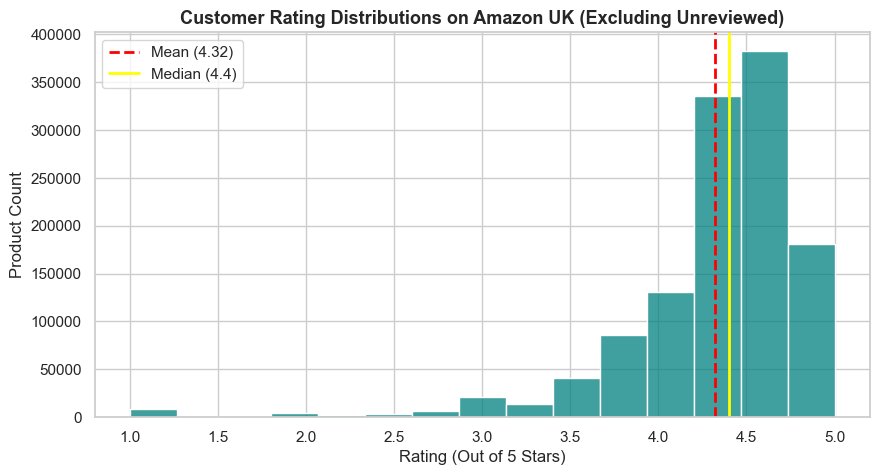

In [29]:
# 3. Shape Calculations (Skewness and Kurtosis)
rating_skew = skew(clean_rating_df['rating'])
rating_kurt = kurtosis(clean_rating_df['rating'])

print("\n--- Cleaned Rating Central Tendency (Reviewed Products Only) ---")
print(f"Mean Rating:   {rating_mean:.2f} Stars")
print(f"Median Rating: {rating_median:.1f} Stars")
print(f"Mode Rating:   {rating_mode:.1f} Stars")

print("\n--- Cleaned Rating Dispersion Measures ---")
print(f"Variance:           {rating_var:.2f}")
print(f"Standard Deviation: {rating_std:.2f} Stars")
print(f"Interquartile Range:{rating_iqr:.2f} Stars")

print("\n--- Cleaned Distribution Shape Metrics ---")
print(f"Skewness Score: {rating_skew:.2f}")
print(f"Kurtosis Score: {rating_kurt:.2f}")

# 4. Visualization
plt.figure(figsize=(10, 5))
sns.histplot(clean_rating_df['rating'], bins=15, kde=False, color='teal')
plt.axvline(rating_mean, color='red', linestyle='--', linewidth=2, label=f'Mean ({rating_mean:.2f})')
plt.axvline(rating_median, color='yellow', linestyle='-', linewidth=2, label=f'Median ({rating_median:.1f})')

plt.title('Customer Rating Distributions on Amazon UK (Excluding Unreviewed)', fontsize=13, fontweight='bold')
plt.xlabel('Rating (Out of 5 Stars)')
plt.ylabel('Product Count')
plt.legend()
plt.show()

# Comprehensive Lab Report: Exploratory Data Analysis on Amazon UK

### 1. Analysis of Product Categories (Part 1 Summary)
* **Market Dynamics**: Our frequency evaluation maps out seller listing concentrations across different product lines. Dense distributions identify highly active categories where standing out requires aggressive organic visibility and targeted optimization strategy.
* **Vertical Domination**: The corresponding visualizations evaluate whether market catalog segments are monopolized by single core categories or balanced evenly across multiple product domains.

### 2. Analysis of Product Pricing (Part 2 Summary)
* **Central Tendency Skew**: The pricing architecture exhibits a distinct mathematical right-skewed dynamic (Mean: £89.24, Median: £19.09, Mode: £9.99). The common marketplace anchor point (Mode) stays low at £9.99, but extreme luxury or industrial listings pull the arithmetic mean significantly upwards.
* **Dispersion Variance**: A massive standard deviation (£345.61) compared to a tight Interquartile Range (£36.00) mathematically confirms that while the core 50% of the active product inventory trades inside a steady budget bracket, the platform supports highly distributed, low-volume, premium product configurations.
* **Visualization Optimization Strategy**: Standard continuous histograms suffer from extreme tail compression due to absolute maximum pricing nodes reaching £100,000.00. We successfully circumvented this structural limitation by clipping the visualization threshold at the 95th percentile to highlight core market purchasing behavior.

### 3. Analysis of Customer Feedback (Part 3 Summary)
* **Sentiment Architecture**: Evaluating reviewed listings exhibits strong satisfaction benchmarks across the entire Amazon UK catalog (Mean: 4.32, Median: 4.4, Mode: 4.5 Stars).
* **Mathematical Curve Distribution**: A solid negative skewness score (-2.38) paired with high leptokurtic kurtosis (9.78) confirms that review distribution is concentrated on positive outcomes. The heavy tails indicate that severe performance drops or critical 1-star reviews represent rare outliers rather than typical buyer behaviors.
